# Predicting Credit Card Default with a Neural Network

**Dataset:** Default of Credit Card Clients, UCI Machine Learning Repository [1]

**Part 2.** Part 1 (`CreditCard_ML_ModelComparison.ipynb`) trained three tree based and classification ML models on
this data. This notebook trains a neural network on the same features and the same train/test
split, then compares all four on the same 6,000 test clients.

## 1. Introduction

The task is unchanged from Part 1: predict whether a credit card client in Taiwan **defaulted
on their October 2005 payment** from six months of billing and repayment history [1]. 22.1% of
clients defaulted, so always predicting "no default" is already 77.9% accurate.

To keep the comparison fair, this notebook repeats Part 1's cleaning, keeps the same
21 features (`SEX` and `MARRIAGE` stay excluded) and reproduces the same stratified 80/20 split
with seed 20. The check at the end of the next cell confirms the test rows match the ones saved
in Part 1, and the three saved Part 1 models are loaded from `models/` in section 4.

In [1]:
import random, time, copy, pathlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split

SEED = 20
random.seed(SEED)                     # same seed as Part 1 (the split itself is fixed by random_state below)
np.random.seed(SEED)
torch.manual_seed(SEED)               # network weights and batch order
MODELS = pathlib.Path("models")       # Part 1's saved models and test rows

uci = fetch_ucirepo(id=350)
names = dict(zip(uci.variables["name"], uci.variables["description"]))
X_raw = uci.data.features.rename(columns=names)
y = uci.data.targets["Y"].rename("default")                        # 1 = defaulted next month

# same cleaning and features as Part 1
PROTECTED = ["SEX", "MARRIAGE"]
X = X_raw.drop(columns=PROTECTED).copy()
X["EDUCATION"] = X["EDUCATION"].replace({0: 4, 5: 4, 6: 4})        # undocumented codes -> 4 ("others")
MONEY = ["LIMIT_BAL"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]
CAT   = ["EDUCATION"]
OTHER = [c for c in X.columns if c not in MONEY + CAT]             # AGE and the six PAY_x statuses

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
saved_rows = pd.read_csv(MODELS / "test_index.csv")["test_row"].values
assert np.array_equal(X_test.index.values, saved_rows), "test rows differ from Part 1"
print(f"train {X_train.shape}  test {X_test.shape} | test rows identical to Part 1: True")

train (24000, 21)  test (6000, 21) | test rows identical to Part 1: True


## 2. Network architecture

A feed-forward network (multilayer perceptron). Each hidden layer is a fully connected layer, a ReLU activation and dropout,
which switches off a random share of units during training so the network cannot lean on any
single one [3]. The output is one number (a logit) that a sigmoid turns into P(default).

**Inputs.** Networks need scaled inputs, so the features get exactly the preprocessing Part 1
gave the SVM and Naive Bayes: money columns through `arcsinh` (log-like, keeps negative bills
negative) then standardised, `AGE` and `PAY_x` standardised, `EDUCATION` one-hot encoded. That
gives 24 inputs. The number and width of the hidden layers and the dropout rate are tuned in
section 3.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, accuracy_score

prep = ColumnTransformer([      # identical to Part 1's preprocessing for SVM and Naive Bayes
    ("money", Pipeline([("asinh", FunctionTransformer(np.arcsinh)),
                        ("scale", StandardScaler())]), MONEY),
    ("other", StandardScaler(), OTHER),
    ("cat",   OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

def tensor(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32)

class DefaultNet(nn.Module):
    # hidden=(128, 64) builds: Linear(24->128), ReLU, Dropout, Linear(128->64), ReLU, Dropout, Linear(64->1)
    def __init__(self, n_in, hidden, dropout):
        super().__init__()
        layers = []
        for width in hidden:
            layers += [nn.Linear(n_in, width), nn.ReLU(), nn.Dropout(dropout)]
            n_in = width
        layers.append(nn.Linear(n_in, 1))                           # one logit per client
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)

def predict_proba(model, Xt):
    model.eval()                                                    # dropout off for prediction
    with torch.no_grad():
        return torch.sigmoid(model(Xt)).numpy()

def train(Xt, yt, hidden, dropout, lr, epochs=200, Xv=None, yv=None, patience=10, batch=256):
    # mini-batch Adam on binary cross-entropy; with a validation set, stop once validation
    # ROC-AUC has not improved for `patience` epochs and keep the best epoch's weights
    torch.manual_seed(SEED)
    model = DefaultNet(Xt.shape[1], hidden, dropout)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    order = torch.Generator().manual_seed(SEED)                     # reproducible batch shuffling
    history, best_auc, best_epoch, best_weights = [], -1, 0, None
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for idx in torch.randperm(len(Xt), generator=order).split(batch):
            opt.zero_grad()
            loss = loss_fn(model(Xt[idx]), yt[idx])
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        row = {"epoch": epoch, "train loss": total / len(Xt)}
        if Xv is not None:
            model.eval()
            with torch.no_grad():
                logit = model(Xv)
            row["val loss"] = loss_fn(logit, yv).item()
            row["val ROC-AUC"] = roc_auc_score(yv.numpy(), logit.numpy())
            if row["val ROC-AUC"] > best_auc:
                best_auc, best_epoch = row["val ROC-AUC"], epoch
                best_weights = copy.deepcopy(model.state_dict())    #takes a snapshot whenever theres a best weight at that epoch
        history.append(row)
        if Xv is not None and epoch - best_epoch >= patience:
            break
    if best_weights is not None:
        model.load_state_dict(best_weights)      #overwites model with actual best weight instead of when the epoch broke 
    return model, pd.DataFrame(history).set_index("epoch"), best_epoch or epochs

## 3. Training process

1. **Validation set.** 20% of the training set (4,800 clients, stratified, seed 20) is held out
   for tuning and early stopping. The test set is not touched until section 4.
2. **Train.** Mini-batches of 256 clients, the Adam optimiser [4] and binary cross-entropy loss,
   for up to 200 epochs. The loss is not reweighted for the 22% default rate, and predictions use
   the 0.5 threshold, both as in Part 1.
3. **Early stopping.** After every epoch the network is scored on the validation set. Training
   stops when validation ROC-AUC has not improved for 10 epochs, and the best epoch's weights
   are kept.
4. **Tune.** 12 settings are tried: three network shapes (one to three hidden layers), two
   dropout rates and two learning rates. As in Part 1, the winner is chosen by ROC-AUC.
5. **Refit and save.** The best setting is retrained on the full 24,000-client training set for
   its best number of epochs and saved to `models/`.

In [ ]:
from itertools import product

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
prep_search = clone(prep).fit(X_fit)                                # scaling learnt on X_fit only
Xf, Xv = tensor(prep_search.transform(X_fit)), tensor(prep_search.transform(X_val))
yf, yv = tensor(y_fit), tensor(y_val)

grid = {"hidden layers": [(64,), (128, 64), (256, 128, 64)],
        "dropout": [0.1, 0.3],
        "learning rate": [1e-3, 1e-4]}

rows, curves = [], {}
for hidden, dropout, lr in product(*grid.values()):
    t0 = time.time()    #calculate how long run takes for each different parameter
    model, hist, best_epoch = train(Xf, yf, hidden, dropout, lr, Xv=Xv, yv=yv)
    p = predict_proba(model, Xv)
    curves[(hidden, dropout, lr)] = hist
    rows.append({"hidden layers": hidden, "dropout": dropout, "learning rate": lr,
                 "best epoch": best_epoch, "val ROC-AUC": roc_auc_score(y_val, p),
                 "val accuracy": accuracy_score(y_val, p >= 0.5),
                 "seconds": round(time.time() - t0)})
search = pd.DataFrame(rows).sort_values("val ROC-AUC", ascending=False).reset_index(drop=True)
search.round({"val ROC-AUC": 3, "val accuracy": 3})

,hidden layers,dropout,learning rate,best epoch,val ROC-AUC,val accuracy,seconds
0,"(256, 128, 64)",0.3,0.0010,21,0.788,0.819,3
1,"(128, 64)",0.3,0.0010,44,0.788,0.818,3
2,"(256, 128, 64)",0.3,0.0001,106,0.787,0.820,10
3,"(256, 128, 64)",0.1,0.0010,12,0.787,0.819,2
4,"(128, 64)",0.1,0.0010,26,0.785,0.820,2
5,"(256, 128, 64)",0.1,0.0001,51,0.784,0.818,6
6,"(128, 64)",0.3,0.0001,197,0.784,0.821,9
7,"(128, 64)",0.1,0.0001,117,0.784,0.820,6
8,"(64,)",0.1,0.0010,42,0.783,0.815,5
9,"(64,)",0.1,0.0001,197,0.782,0.818,5


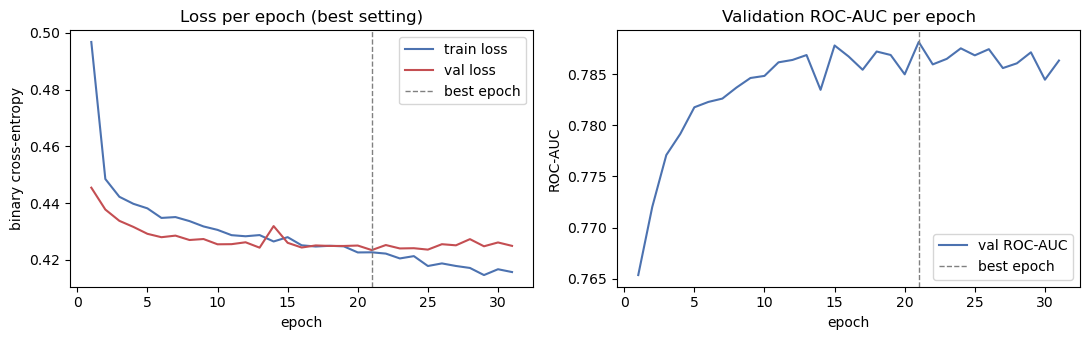

In [4]:
best = search.iloc[0]
hist = curves[(best["hidden layers"], best["dropout"], best["learning rate"])]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
hist[["train loss", "val loss"]].plot(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set(title="Loss per epoch (best setting)", ylabel="binary cross-entropy")
hist["val ROC-AUC"].plot(ax=ax[1], color="#4C72B0")
ax[1].set(title="Validation ROC-AUC per epoch", ylabel="ROC-AUC")
for a in ax:
    a.axvline(best["best epoch"], color="grey", ls="--", lw=1, label="best epoch")
    a.legend()
plt.tight_layout(); plt.show()

**Tuning result.** The best setting is the deepest network: three hidden layers of 256, 128 and
64 units, dropout 0.3 and learning rate 0.001 (validation ROC-AUC 0.788, best at epoch 21). The
ranking matters less than it looks. The top five settings are within 0.003 of each other, well
inside the fold-to-fold spread of about 0.01 seen in Part 1, and even the one-layer network
reaches 0.783, so extra depth and width buy very little. The higher learning rate converges in
12 to 44 epochs against 51 to 197 for the lower one. Three of the slow runs were still creeping
up at the 200-epoch cap, but they sat 0.004 or more below the leader.

The loss curves show early stopping doing its job. Training loss starts above validation loss
because dropout is active during training, then keeps falling while validation loss flattens
after about epoch 15: from there on the network is fitting the training clients more closely
without getting better on new ones.

In [5]:
import joblib

# final network: best setting, retrained on all 24,000 training clients for its best epoch count
prep_final = clone(prep).fit(X_train)
Xtr, Xte = tensor(prep_final.transform(X_train)), tensor(prep_final.transform(X_test))
setting = dict(hidden=best["hidden layers"], dropout=best["dropout"], lr=best["learning rate"])
net, _, _ = train(Xtr, tensor(y_train), **setting, epochs=int(best["best epoch"]))

torch.save({"state_dict": net.state_dict(), "n_in": Xtr.shape[1], **setting},
           MODELS / "neural_network.pt")
joblib.dump(prep_final, MODELS / "neural_network_prep.joblib")       # the scaling it expects
n_params = sum(p.numel() for p in net.parameters())
print(f"network {setting['hidden']}: {n_params:,} weights, {int(best['best epoch'])} epochs | "
      "saved neural_network.pt, neural_network_prep.joblib")

network (256, 128, 64): 47,617 weights, 21 epochs | saved neural_network.pt, neural_network_prep.joblib


## 4. Evaluation

### Quantitative

The network is scored with the same metrics as Part 1, next to the three saved Part 1 models and
the majority-class reference: accuracy (the brief's headline), precision and recall for
defaulters, F1, and ROC-AUC (how well each model ranks defaulters above non-defaulters, whatever
the threshold).

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

stat = {name: joblib.load(MODELS / f"{file}.joblib") for name, file in
        [("Random forest", "random_forest"), ("SVM (RBF)", "svm"), ("Naive Bayes", "naive_bayes")]}

def score(model):   # continuous score for ROC-AUC: probability, or the SVM's distance from the margin
    return model.decision_function(X_test) if hasattr(model, "decision_function") else model.predict_proba(X_test)[:, 1]

scores = {name: score(m) for name, m in stat.items()}
scores["Neural network"] = predict_proba(net, Xte)
pred = {name: m.predict(X_test) for name, m in stat.items()}
pred["Neural network"] = (scores["Neural network"] >= 0.5).astype(int)

ref = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)    # always "no default"
table = pd.DataFrame({name: {
    "accuracy":  accuracy_score(y_test, p),
    "precision": precision_score(y_test, p, zero_division=0),
    "recall":    recall_score(y_test, p),
    "F1":        f1_score(y_test, p, zero_division=0),
    "ROC-AUC":   roc_auc_score(y_test, s)}
    for name, p, s in [("Majority-class reference", ref.predict(X_test), np.zeros(len(y_test)))]
                     + [(n, pred[n], scores[n]) for n in pred]}).T
table.round(3)

,accuracy,precision,recall,F1,ROC-AUC
Majority-class reference,0.779,0.000,0.000,0.000,0.500
Random forest,0.821,0.681,0.356,0.467,0.771
SVM (RBF),0.817,0.684,0.320,0.436,0.702
Naive Bayes,0.754,0.451,0.523,0.484,0.736
Neural network,0.820,0.668,0.371,0.477,0.770


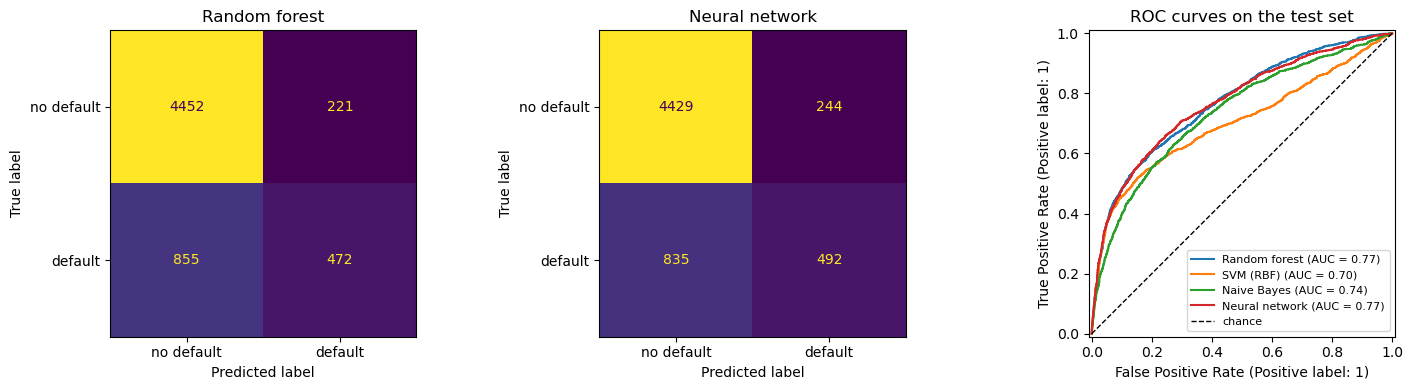

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, name in zip(ax[:2], ["Random forest", "Neural network"]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred[name], ax=a, colorbar=False,
                                            display_labels=["no default", "default"])
    a.set_title(name)
for name, s in scores.items():
    RocCurveDisplay.from_predictions(y_test, s, name=name, ax=ax[2])
ax[2].plot([0, 1], [0, 1], "k--", lw=1, label="chance")
ax[2].set_title("ROC curves on the test set"); ax[2].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
from statsmodels.stats.contingency_tables import mcnemar

# McNemar's test [5]: does the network make a different number of mistakes than each Part 1 model?
correct = {name: p == y_test.values for name, p in pred.items()}
rows = []
for other in stat:
    a, b = correct["Neural network"], correct[other]
    res = mcnemar([[(a & b).sum(), (a & ~b).sum()], [(~a & b).sum(), (~a & ~b).sum()]],
                  exact=False, correction=True)
    rows.append({"pair": f"Neural network vs {other}", "only network right": int((a & ~b).sum()),
                 "only other right": int((~a & b).sum()), "p-value": f"{res.pvalue:.2g}"})
pd.DataFrame(rows).set_index("pair")

,only network right,only other right,p-value
pair,,,
Neural network vs Random forest,72,75,0.87
Neural network vs SVM (RBF),88,69,0.15
Neural network vs Naive Bayes,717,319,5.9e-35


**Result**

- **The network ties the random forest.** Accuracy 0.820 against 0.821, ROC-AUC 0.770 against
  0.771. McNemar's test finds no difference (p = 0.87): of 6,000 test clients, 72 are classified
  correctly only by the network and 75 only by the forest.
- **It is slightly less cautious.** It flags 736 clients against the forest's 693, catching 492
  defaulters instead of 472 (recall 0.371 against 0.356) for 23 more false alarms. It still
  misses 63% of defaulters at the 0.5 threshold.
- **It ranks clients much better than the SVM** (ROC-AUC 0.770 against 0.702), although their
  accuracy is not significantly different (p = 0.15), and it is far more accurate than Naive
  Bayes (p < 1e-34).
- **No sign of overfitting the tuning.** The network dropped from 0.788 on validation to 0.770
  on test; the forest dropped from 0.784 in cross-validation to 0.771. Both fall by a similar
  amount.

### Qualitative: specific clients

The first four rows are the same four test clients Part 1 examined, one from each pattern of
agreement between the statistical models, now with the network's probability added. The last two
are clients where the network and the random forest disagree. The printout shows how often the
network flags each group as a defaulter.

In [9]:
rf, sv, nb, nnet = (pred[n] for n in ["Random forest", "SVM (RBF)", "Naive Bayes", "Neural network"])
actual = y_test.values
cases = {
    "all three catch a defaulter":    (actual == 1) & (rf == 1) & (sv == 1) & (nb == 1),   # Part 1's four
    "all three miss a defaulter":     (actual == 1) & (rf == 0) & (sv == 0) & (nb == 0),
    "all three flag a non-defaulter": (actual == 0) & (rf == 1) & (sv == 1) & (nb == 1),
    "only Naive Bayes flags":         (nb == 1) & (rf == 0) & (sv == 0),
    "network right, forest wrong":    (nnet == actual) & (rf != actual),
    "forest right, network wrong":    (rf == actual) & (nnet != actual),
}
for label, mask in cases.items():
    print(f"{label:32s} {mask.sum():4d} clients | network flags {nnet[mask].sum():4d} ({nnet[mask].mean():.0%})")

# how similar the network and the forest are overall, and how borderline their disagreements are
rf_prob, nn_prob, differ = stat["Random forest"].predict_proba(X_test)[:, 1], scores["Neural network"], nnet != rf
print(f"\nnetwork vs forest: same prediction for {1 - differ.mean():.1%} of clients, "
      f"probability correlation {np.corrcoef(rf_prob, nn_prob)[0, 1]:.2f} | where they differ, "
      f"median distance from 0.5: network {np.median(abs(nn_prob[differ] - 0.5)):.2f}, "
      f"forest {np.median(abs(rf_prob[differ] - 0.5)):.2f}")

cols = ["LIMIT_BAL", "AGE", "PAY_0", "PAY_2", "PAY_3", "BILL_AMT1", "PAY_AMT1"]
view = X_test[cols].assign(
    actual=actual,
    **{"RF P(default)": rf_prob.round(2),
       "SVM score":     scores["SVM (RBF)"].round(2),
       "NB P(default)": stat["Naive Bayes"].predict_proba(X_test)[:, 1].round(2),
       "NN P(default)": scores["Neural network"].round(2)})
pd.concat([view[mask].head(1).assign(case=label) for label, mask in cases.items()]).set_index("case")

all three catch a defaulter       329 clients | network flags  325 (99%)
all three miss a defaulter        553 clients | network flags    1 (0%)
all three flag a non-defaulter    138 clients | network flags  133 (96%)
only Naive Bayes flags            930 clients | network flags   62 (7%)
network right, forest wrong        72 clients | network flags   48 (67%)
forest right, network wrong        75 clients | network flags   47 (63%)

network vs forest: same prediction for 97.5% of clients, probability correlation 0.95 | where they differ, median distance from 0.5: network 0.04, forest 0.04


,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,BILL_AMT1,PAY_AMT1,actual,RF P(default),SVM score,NB P(default),NN P(default)
case,,,,,,,,,,,,
all three catch a defaulter,300000,40,-1,3,2,5130,0,1,0.64,0.56,1.00,0.58
all three miss a defaulter,240000,48,0,-1,-1,3972,783,1,0.11,-1.05,0.05,0.17
all three flag a non-defaulter,360000,34,2,2,-2,2500,0,0,0.70,0.21,1.00,0.70
only Naive Bayes flags,200000,36,-2,-2,-2,0,0,1,0.27,-1.00,0.89,0.37
"network right, forest wrong",50000,37,1,2,2,14008,0,1,0.48,0.27,1.00,0.53
"forest right, network wrong",140000,32,1,2,2,67923,3200,1,0.58,-0.08,1.00,0.47


**What the examples show**

- **Where the statistical models agree, so does the network.** It flags 99% of the 329
  defaulters all three other models caught and 96% of the 138 non-defaulters all three wrongly flagged. On
  Part 1's example clients its probabilities (0.58, 0.17, 0.70) sit close to the forest's (0.64,
  0.11, 0.70).
- **The network finds no hidden signal in the hardest cases.** Of the 553 defaulters every
  statistical model missed, it catches one. That leaves 552 defaulters, 42% of the 1,327 in the
  test set, missed by all four models: clients like the 48-year-old in row 2, who paid on time and
  carried a small balance.
- **It does not share Naive Bayes's mistake.** For the inactive client with a zero balance it
  gives 0.37 (forest 0.27, Naive Bayes 0.89), and it flags only 7% of the 930 clients that only
  Naive Bayes flagged.
- **Its disagreements with the forest are coin flips.** The two make the same prediction for
  97.5% of clients and their probabilities correlate at 0.95. Where they disagree, both are
  typically within 0.04 of the threshold, like the last two rows (0.53 against 0.48, and 0.47
  against 0.58): both clients were 1 to 2 months late, and neither model has grounds to be sure.

## 5. Comparison with the statistical models

The network matches the random forest, the best Part 1 model, and beats the SVM and Naive Bayes.
It does not beat the forest, so on this data the extra machinery buys no accuracy.

| | Neural network | Random forest |
|---|---|---|
| Test accuracy / ROC-AUC | 0.820 / 0.770 | 0.821 / 0.771 |
| Preprocessing | scaling and one-hot encoding required | none |
| Settings to choose | layers, widths, dropout, learning rate, epochs, batch size | tree depth, leaf size |
| Explaining a prediction | needs extra tools | permutation importance (Part 1) |

**Verdict.** The random forest remains the better choice for this problem: the same accuracy with
no preprocessing, fewer settings to tune, and predictions that are easier to explain to a lender.
This matches the wider finding that tree ensembles still match or beat deep networks on
medium-sized tables of features [6]. A network would earn its place with far more clients, or
with inputs a forest handles poorly, such as raw monthly transaction sequences.

**Limitations**

- **Same 0.5 threshold and unweighted loss as Part 1**, which keeps the comparison fair but leaves
  recall low for every model.
- **Tuned on one validation split**, not 5-fold cross-validation like Part 1, so the gaps
  between the top settings are within noise.

## References

1. Yeh, I.-C., & Lien, C.-H. (2009). *Default of credit card clients* [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
2. Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., et al. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems*, 32. https://arxiv.org/abs/1912.01703
3. Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research*, 15(56), 1929-1958. https://jmlr.org/papers/v15/srivastava14a.html
4. Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *International Conference on Learning Representations*. https://arxiv.org/abs/1412.6980
5. Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7), 1895-1923. https://doi.org/10.1162/089976698300017197
6. Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems*, 35, 507-520. https://arxiv.org/abs/2207.08815